# LEAR on New Data — ENTSO-E 2019–2023

**Purpose:** Test robustness of the accuracy vs. decision-value divergence during the  
2022 energy crisis — a much more volatile period than the 2015–2018 benchmark.

**Hypothesis:** If the divergence is driven by tail events, it should be *larger* in  
2022–2023 (energy crisis, extreme prices, nuclear outages in FR/BE).

**Data:** ENTSO-E day-ahead prices 2019–2023 (`data/raw/entso_e/`).  
Price-only — no load/generation forecast available.  
We use a price-lag only version of LEAR (AR-LEAR), setting Exogenous 1 = Exogenous 2 = 0.  
This is a simplification — flagged in the thesis as a limitation.

**Markets:** FR, BE, NP, DE (4 European markets; PJM excluded — no 2019–2023 data).

**Train window:** 2017-01-01 → 2021-12-31 (4 years)  
**Test window:** 2022-01-01 → 2023-12-31 (2 years)

**Structure:**
- Section 0: Setup & data loading
- Section 1: AR-LEAR retrain on 2022–2023
- Section 2: Decision regret Phase 4 on 2022–2023
- Section 3: DM tests Phase 5 — compare AR-LEAR vs published LEAR regret
- Section 4: Key figure — regret gap 2016–2018 vs 2022–2023


> **Revision of 14 Oct 2026** (feedback of 13 Oct 2026). (1) Regret now uses the shared `decision_utils.py`: predictive distribution p̂_t + (p_s − p̂_s) as in thesis eq. 3.5 (the previous code mirrored it) and a daily two-sided DM test. (2) The forward proxy now uses past prices only (`shift(1)`), as in the benchmark notebooks; the previous version included the current hour's price in its own forward price. (3) `RETRAIN = False` (default) loads the AR-LEAR forecasts saved in `model_outputs/retrained_forecasts/`, so the regret sections run from the repository; `RETRAIN = True` re-runs the retraining and needs `epftoolbox` and the raw ENTSO-E files. (4) Only one model is evaluated per period here, so this notebook describes how regret behaves in the 2022–2023 regime; it does not test the accuracy-versus-value gap, which needs two models.

---
## Section 0 — Setup & Data Loading

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from decision_utils import (ROOT, RETRAINED_DIR, FIG_DIR, WINDOW, ALPHA, PREMIUM, LAMBDAS,
                            forward_proxy, compute_regret, dm_test)

# RETRAIN = True re-runs the AR-LEAR retraining (needs epftoolbox and the raw ENTSO-E files,
# about 1–2 h). RETRAIN = False loads the forecasts saved in model_outputs/retrained_forecasts/.
RETRAIN = False
if RETRAIN:
    sys.path.insert(0, str(ROOT / 'epftoolbox'))
    from epftoolbox.models import LEAR

# ── Paths ─────────────────────────────────────────────────────────────────
ENTSO_PATH     = str(ROOT / 'data' / 'raw' / 'entso_e') + '/'
OUT_PATH       = str(RETRAINED_DIR) + '/'
BENCHMARK_PATH = OUT_PATH          # 2016–2018 LEAR forecasts saved by train_models.ipynb
FIG_DIR.mkdir(parents=True, exist_ok=True)

MARKETS_NEW = ['FR', 'BE', 'NP', 'DE']   # PJM excluded — no 2019-2023 data

# Train on 4 years, test on 2022-2023
TRAIN_START  = '2017-01-01'
TEST_START   = '2022-01-01'
TEST_END     = '2023-12-30'
TRAIN_WINDOW = 1456   # days (paper default, reuse same as benchmark)

print('Setup complete.')
print(f'Markets : {MARKETS_NEW}')
print(f'Test    : {TEST_START} → {TEST_END}')
print(f'Retrain : {RETRAIN}')

Setup complete.
Markets : ['FR', 'BE', 'NP', 'DE']
Test    : 2022-01-01 → 2023-12-30
Retrain : False


In [2]:
def load_entso_price(market):
    """
    Load ENTSO-E day-ahead price CSV.
    Returns DataFrame with UTC DatetimeIndex and a single 'Price' column.
    No exogenous columns — LEAR infers n_exogenous_inputs=0 from the column count
    and skips the exogenous feature loop entirely.
    """
    path = ENTSO_PATH + f'{market}_dayahead_2019_2023.csv'
    df = pd.read_csv(path, index_col=0)
    df.columns = ['Price']
    df.index = pd.to_datetime(df.index, utc=True).tz_localize(None)  # naive UTC
    df = df.asfreq('h')

    # FR/BE/NP are missing Dec 31 00:00 local time every year in the ENTSO-E source.
    df['Price'] = df['Price'].ffill(limit=1)

    # LEAR's _build_and_split_XYs assumes the index starts at hour 0 and strides
    # in 24-hour blocks. After CET->UTC conversion the data starts at hour 23.
    # Trim to the first midnight and the last hour-23, so every "day" is complete.
    first_midnight = df.index[df.index.hour == 0][0]
    last_h23 = df.index[df.index.hour == 23][-1]
    df = df.loc[first_midnight:last_h23]

    return df


all_data_new = {}
if os.path.isdir(ENTSO_PATH):
    print('Loading ENTSO-E data...')
    for mkt in MARKETS_NEW:
        df = load_entso_price(mkt)
        all_data_new[mkt] = df
        nan_p  = df['Price'].isna().sum()
        n_neg  = (df['Price'] < 0).sum()
        print(f'  {mkt}: {len(df):,} rows  '
              f'{df.index[0]} (h={df.index[0].hour}) -> '
              f'{df.index[-1]} (h={df.index[-1].hour})  '
              f'NaN={nan_p}  negative={n_neg}')
else:
    print('Raw ENTSO-E files are not in the repository (data/raw/entso_e/): loading skipped.')

print()
print('Note: price-only (no exogenous) -> AR-LEAR, n_exogenous_inputs=0')

Raw ENTSO-E files are not in the repository (data/raw/entso_e/): loading skipped.

Note: price-only (no exogenous) -> AR-LEAR, n_exogenous_inputs=0


In [3]:
# compute_regret and dm_test are imported from decision_utils.py (first cell): same predictive
# distribution (thesis eq. 3.5), decision rule and DM test as the benchmark notebooks.
print('Helper functions imported from decision_utils.py.')

Helper functions imported from decision_utils.py.


---
## Section 1 — AR-LEAR Retrain on 2022–2023

Train on 1456 days ending 2021-12-31, roll forward through 2022-2023.  
4 calibration windows (56, 84, 1092, 1456) → ensemble = element-wise mean.  
No published MAE to gate against — compare to 2016-2018 benchmark as reference.

In [4]:
LEAR_WINDOWS_NEW = [84, 1092, 1456]   # skip 56 (underdetermined for short windows)

def retrain_lear_rolling_new(df, test_start, test_end, calibration_window):
    """
    Rolling LEAR retrain on ENTSO-E price-only data.
    Returns DataFrame [real, forecast] with hourly DatetimeIndex.
    """
    model = LEAR(calibration_window=calibration_window)
    test_dates = pd.date_range(test_start, test_end, freq='D')
    records = []
    for i, date in enumerate(test_dates):
        if (i + 1) % 200 == 0 or i == 0:
            print(f'    w={calibration_window}d  day {i+1}/{len(test_dates)}: {date.date()}',
                  flush=True)
        Yp   = model.recalibrate_and_forecast_next_day(
            df=df, calibration_window=calibration_window, next_day_date=date
        ).flatten()
        real = df.loc[date : date + pd.Timedelta(hours=23), 'Price'].values
        for h in range(24):
            records.append({
                'datetime' : date + pd.Timedelta(hours=h),
                'real'     : real[h],
                'forecast' : Yp[h],
            })
    return pd.DataFrame(records).set_index('datetime')


def retrain_lear_ensemble_new(df, test_start, test_end, windows=LEAR_WINDOWS_NEW):
    """Train one window at a time, return ensemble mean + per-window dict."""
    per_win = {}
    for w in windows:
        print(f'  Window {w} days ...', flush=True)
        per_win[w] = retrain_lear_rolling_new(df, test_start, test_end, w)
    fcst_ens = per_win[windows[0]].copy()
    fcst_ens['forecast'] = np.mean(
        [per_win[w]['forecast'].values for w in windows], axis=0
    )
    return fcst_ens, per_win


print('LEAR functions defined.')
print(f'Windows: {LEAR_WINDOWS_NEW}  (56 skipped — underdetermined with price-only features)')

LEAR functions defined.
Windows: [84, 1092, 1456]  (56 skipped — underdetermined with price-only features)


In [5]:
# ── AR-LEAR forecasts for 2022-2023: retrain, or load the saved ones ──────
# Runtime estimate when retraining: ~1-2 hrs total (3 windows × 730 days × 4 markets)
# Benchmark MAEs for 2016-2018 (from LEAR retrained in train_models.ipynb)
BENCHMARK_MAE_1618 = {
    'NP': 1.738, 'BE': 6.140, 'FR': 3.980, 'DE': 3.609
}

all_fcst_new = {}
for mkt in MARKETS_NEW:
    if RETRAIN:
        print(f'\nRetraining AR-LEAR on {mkt} (2022-2023) ...')
        fcst_ens, per_win = retrain_lear_ensemble_new(all_data_new[mkt], TEST_START, TEST_END)
        fcst_ens.to_csv(OUT_PATH + f'{mkt}_ARLEAR_entso_2022_2023.csv')
    else:
        fcst_ens = pd.read_csv(OUT_PATH + f'{mkt}_ARLEAR_entso_2022_2023.csv',
                               index_col=0, parse_dates=True)
    all_fcst_new[mkt] = fcst_ens

    mae  = float(np.mean(np.abs(fcst_ens['forecast'] - fcst_ens['real'])))
    ref  = BENCHMARK_MAE_1618.get(mkt, float('nan'))
    print(f'  {mkt} MAE (2022-2023): {mae:.4f}  |  ref 2016-2018: {ref:.4f}  '
          f'({"higher" if mae > ref else "lower"} than benchmark)')

print('\nAR-LEAR forecasts ready.')

  FR MAE (2022-2023): 24.0169  |  ref 2016-2018: 3.9800  (higher than benchmark)
  BE MAE (2022-2023): 29.2620  |  ref 2016-2018: 6.1400  (higher than benchmark)
  NP MAE (2022-2023): 17.5991  |  ref 2016-2018: 1.7380  (higher than benchmark)
  DE MAE (2022-2023): 30.3070  |  ref 2016-2018: 3.6090  (higher than benchmark)

AR-LEAR forecasts ready.


---
## Section 2 — Phase 4: Decision Regret on 2022–2023

Same `compute_regret` pipeline as in `cross_market_decision.ipynb`.  
Forward price proxy: rolling 90-day mean × (1 + 5%).

In [6]:
def build_regret_df(fcst_df):
    '''
    Convert [real, forecast] DataFrame into the format expected by compute_regret.
    Adds the forward price proxy: rolling 90-day mean of PAST prices × (1 + PREMIUM),
    exactly as in the benchmark notebooks (the current hour is excluded).
    '''
    df = fcst_df[['real', 'forecast']].copy()
    df.columns = ['Real price', 'Forecast']
    df['forward'] = forward_proxy(df['Real price'], WINDOW, PREMIUM)
    return df


all_regret_new = {}
print('Computing decision regret on 2022-2023 ...')
print(f'CVaR α = {ALPHA}  |  Rolling window = {WINDOW//24} days\n')

for mkt in MARKETS_NEW:
    df_r = build_regret_df(all_fcst_new[mkt])
    regret = compute_regret(df_r, 'Forecast', df_r['forward'], WINDOW, ALPHA, LAMBDAS)
    all_regret_new[mkt] = regret
    print(f'{mkt}: mean regret  λ=0 = {regret["regret_λ=0.0"].mean():.4f}   '
          f'λ=1 = {regret["regret_λ=1.0"].mean():.4f}')

print('\nDone.')

Computing decision regret on 2022-2023 ...
CVaR α = 0.1  |  Rolling window = 90 days



FR: mean regret  λ=0 = 1.7734   λ=1 = 15.3204


BE: mean regret  λ=0 = 2.6316   λ=1 = 17.3971


NP: mean regret  λ=0 = 1.4751   λ=1 = 12.9435


DE: mean regret  λ=0 = 2.7509   λ=1 = 18.2544

Done.


---
## Section 3 — Phase 5: DM Tests on 2022–2023

Compare AR-LEAR regret losses at each λ vs the oracle (regret = 0 baseline).  
Also: compare regret magnitude 2022-2023 vs 2016-2018 published benchmark.

In [7]:
# Load 2016-2018 LEAR retrained forecasts (saved by train_models.ipynb)
# to compute regret on the benchmark period for comparison
all_fcst_1618 = {}
for mkt in MARKETS_NEW:
    csv = BENCHMARK_PATH + f'{mkt}_LEAR_zenodo_baseline.csv'
    if os.path.exists(csv):
        all_fcst_1618[mkt] = pd.read_csv(csv, index_col=0, parse_dates=True)
        print(f'Loaded {mkt} 2016-2018: {len(all_fcst_1618[mkt]):,} rows')
    else:
        print(f'⚠ {mkt} 2016-2018 file not found: {csv}')

Loaded FR 2016-2018: 17,472 rows
Loaded BE 2016-2018: 17,472 rows
Loaded NP 2016-2018: 17,472 rows
Loaded DE 2016-2018: 17,472 rows


In [8]:
# Compute regret on 2016-2018 data for the same markets
all_regret_1618 = {}
for mkt in [m for m in MARKETS_NEW if m in all_fcst_1618]:
    df_r = build_regret_df(all_fcst_1618[mkt])
    regret = compute_regret(
        df_r, 'Forecast', df_r['forward'], WINDOW, ALPHA, LAMBDAS
    )
    all_regret_1618[mkt] = regret

print('Regret computed on 2016-2018 period.')

Regret computed on 2016-2018 period.


In [9]:
# ── Comparison table: 2016-2018 vs 2022-2023 ──────────────────────────────
print('='*80)
print('REGRET COMPARISON — 2016-2018 (benchmark) vs 2022-2023 (energy crisis)')
print('2016-18: LEAR retrained with exogenous inputs  |  2022-23: AR-LEAR (price lags only)')
print('Mean regret (EUR/MWh)')
print('='*80)
print(f"{'Market':6}  {'2016-18 λ=0':>12}  {'2016-18 λ=1':>12}  "
      f"{'2022-23 λ=0':>12}  {'2022-23 λ=1':>12}  {'Ratio λ=1':>10}")
print('-'*70)

for mkt in MARKETS_NEW:
    if mkt not in all_regret_1618 or mkt not in all_regret_new:
        print(f'{mkt:6}  (data not available)')
        continue
    r1618_0 = all_regret_1618[mkt]['regret_λ=0.0'].mean()
    r1618_1 = all_regret_1618[mkt]['regret_λ=1.0'].mean()
    r2223_0 = all_regret_new[mkt]['regret_λ=0.0'].mean()
    r2223_1 = all_regret_new[mkt]['regret_λ=1.0'].mean()
    ratio   = r2223_1 / r1618_1 if r1618_1 > 1e-6 else float('nan')
    print(f"{mkt:6}  {r1618_0:12.4f}  {r1618_1:12.4f}  "
          f"{r2223_0:12.4f}  {r2223_1:12.4f}  {ratio:10.2f}×")

print('='*80)
print()
print('Ratio > 1 → energy crisis period has higher regret (worse tail forecasting)')
print('Hypothesis: ratio > 1 for all markets, especially FR and BE (nuclear outages 2022)')

REGRET COMPARISON — 2016-2018 (benchmark) vs 2022-2023 (energy crisis)
2016-18: LEAR retrained with exogenous inputs  |  2022-23: AR-LEAR (price lags only)
Mean regret (EUR/MWh)
Market   2016-18 λ=0   2016-18 λ=1   2022-23 λ=0   2022-23 λ=1   Ratio λ=1
----------------------------------------------------------------------
FR            0.3783        1.9444        1.7734       15.3204        7.88×
BE            0.8698        5.4230        2.6316       17.3971        3.21×
NP            0.1038        1.1233        1.4751       12.9435       11.52×
DE            0.2408        1.9154        2.7509       18.2544        9.53×

Ratio > 1 → energy crisis period has higher regret (worse tail forecasting)
Hypothesis: ratio > 1 for all markets, especially FR and BE (nuclear outages 2022)


---
## Section 4 — Figure: Regret vs λ — Two Periods

Centrepiece figure comparing the accuracy/value gap across the two time periods.

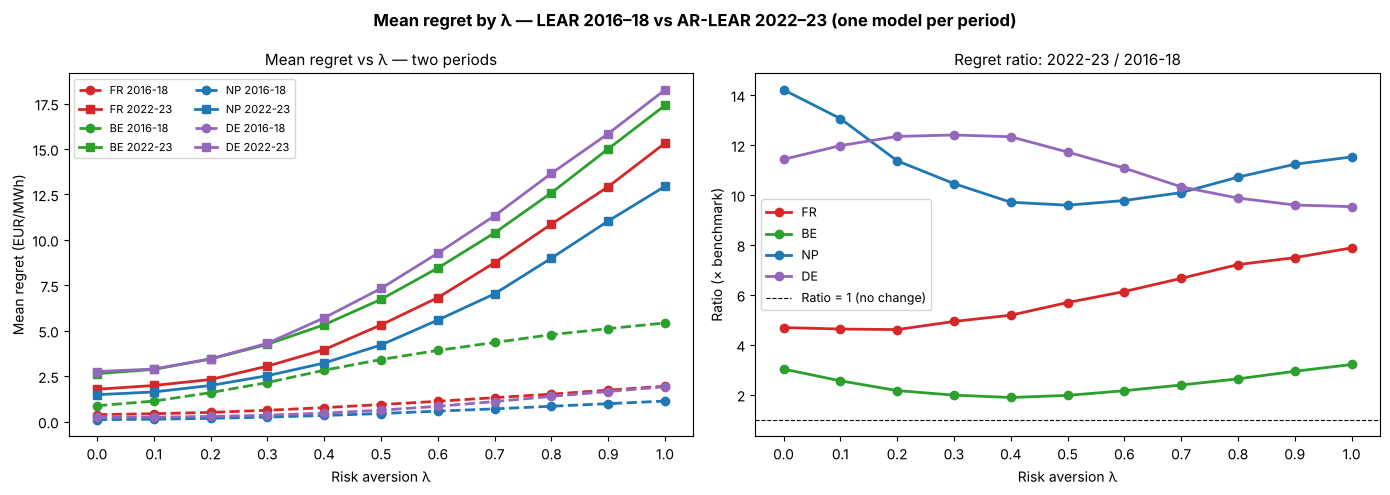

Saved: figures/new_period_regret_comparison.png


In [10]:
colors = {'FR': '#d62728', 'BE': '#2ca02c', 'NP': '#1f77b4', 'DE': '#9467bd'}
lam_vals = LAMBDAS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for mkt in MARKETS_NEW:
    if mkt not in all_regret_1618 or mkt not in all_regret_new:
        continue
    c = colors[mkt]

    # 2016-2018
    r1618 = [all_regret_1618[mkt][f'regret_λ={l:.1f}'].mean() for l in lam_vals]
    axes[0].plot(lam_vals, r1618, color=c, marker='o', linewidth=2,
                 linestyle='--', label=f'{mkt} 2016-18')

    # 2022-2023
    r2223 = [all_regret_new[mkt][f'regret_λ={l:.1f}'].mean() for l in lam_vals]
    axes[0].plot(lam_vals, r2223, color=c, marker='s', linewidth=2,
                 linestyle='-', label=f'{mkt} 2022-23')

axes[0].set_title('Mean regret vs λ — two periods', fontsize=11)
axes[0].set_xlabel('Risk aversion λ')
axes[0].set_ylabel('Mean regret (EUR/MWh)')
axes[0].legend(fontsize=8, ncol=2)
axes[0].set_xticks(lam_vals)

# Right panel: ratio 2022-23 / 2016-18 at each λ
for mkt in MARKETS_NEW:
    if mkt not in all_regret_1618 or mkt not in all_regret_new:
        continue
    ratio = []
    for l in lam_vals:
        col = f'regret_λ={l:.1f}'
        r1 = all_regret_1618[mkt][col].mean()
        r2 = all_regret_new[mkt][col].mean()
        ratio.append(r2 / r1 if r1 > 1e-6 else float('nan'))
    axes[1].plot(lam_vals, ratio, color=colors[mkt], marker='o', linewidth=2, label=mkt)

axes[1].axhline(1, color='black', linestyle='--', linewidth=0.8, label='Ratio = 1 (no change)')
axes[1].set_title('Regret ratio: 2022-23 / 2016-18', fontsize=11)
axes[1].set_xlabel('Risk aversion λ')
axes[1].set_ylabel('Ratio (× benchmark)')
axes[1].legend(fontsize=9)
axes[1].set_xticks(lam_vals)

plt.suptitle('Mean regret by λ — LEAR 2016–18 vs AR-LEAR 2022–23 (one model per period)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'new_period_regret_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/new_period_regret_comparison.png')

In [11]:
# ── Quick stats: kurtosis and negative price count by period ──────────────
from scipy.stats import kurtosis

if not all_data_new:
    print('Raw ENTSO-E prices not loaded (files not in the repository): skipped.')
else:
    print('PRICE DISTRIBUTION COMPARISON')
    print(f"{'Market':6}  {'Kurt 2022-23':>13}  {'Neg prices 22-23':>18}  {'p99 2022-23':>12}")
    print('-'*60)
    for mkt in MARKETS_NEW:
        p = all_data_new[mkt].loc[TEST_START:TEST_END, 'Price'].dropna()
        kurt  = float(kurtosis(p, fisher=True))   # excess kurtosis
        n_neg = int((p < 0).sum())
        p99   = float(np.percentile(p, 99))
        print(f"{mkt:6}  {kurt:13.2f}  {n_neg:18d}  {p99:12.1f} EUR/MWh")

Raw ENTSO-E prices not loaded (files not in the repository): skipped.
